# Data – Báo cáo phân tích và quản lý dữ liệu cho CyberMLOps

> Báo cáo này mô tả **phần Dữ liệu** (Giai đoạn 1) của dự án: nguồn dữ liệu, kết quả phân tích khám phá (EDA) trên **dữ liệu thật**, các quyết định xử lý rút ra từ EDA, và cách chia tập.
> Mọi con số bên dưới được tạo bởi code trong `src/data/` và lưu ở `reports/data/` (có thể chạy lại, xem [mục 8](#8-cách-chạy-lại)).

> **Trạng thái:** EDA đã hoàn thành. Các bước làm sạch, gán nhãn, chia tập và tiền xử lý **mới ở mức đề xuất** (mục 3 đến 5), chưa cài đặt. Những chỗ cần nhóm xác nhận được ghi rõ.

---

## Mục lục

1. [Nguồn dữ liệu](#1-nguồn-dữ-liệu)
2. [Kết quả EDA](#2-kết-quả-eda)
3. [Quyết định xử lý rút ra từ EDA](#3-quyết-định-xử-lý-rút-ra-từ-eda)
4. [Pipeline dữ liệu](#4-pipeline-dữ-liệu)
5. [Chia tập và kịch bản Drift](#5-chia-tập-và-kịch-bản-drift)
6. [Version hóa và tái lập](#6-version-hóa-và-tái-lập)
7. [Cấu trúc thư mục và đầu ra](#7-cấu-trúc-thư-mục-và-đầu-ra)
8. [Cách chạy lại](#8-cách-chạy-lại)
9. [Rủi ro và lưu ý](#9-rủi-ro-và-lưu-ý)
10. [Checklist](#10-checklist)
11. [Data Card](#11-data-card)

---

## 1. Nguồn dữ liệu

| Hạng mục | Nội dung |
|---|---|
| Bộ dữ liệu | CSE-CIC-IDS2018 (CSE và Canadian Institute for Cybersecurity) |
| Nguồn tải | AWS Open Data, bucket công khai `s3://cse-cic-ids2018/Processed Traffic Data for ML Algorithms/` (không cần tài khoản). Trang: <https://registry.opendata.aws/cse-cic-ids2018/> |
| Trang gốc | <https://www.unb.ca/cic/datasets/ids-2018.html> |
| Định dạng | 10 file CSV (mỗi file một ngày), đặc trưng mức luồng mạng trích bằng CICFlowMeter |
| Dung lượng | 6,4 GiB (4,05 GB riêng file ngày 20/02) |
| Kiểm tra toàn vẹn | Dung lượng 10 file khớp từng byte với nguồn; checksum SHA-256 trong `data/raw/MANIFEST.json` |

**Lưu ý về bản Kaggle:** bản Kaggle `primus11/cic-ids-2018-dataset` chỉ có một file (ngày 14/02) nên không dùng; chi tiết ở `HUONG_DAN_DATA.md`.

> `data/raw/cic.csv` là bản tải cũ từ Kaggle, **giống hệt** `Wednesday-14-02-2018...csv` (cùng SHA-256). Pipeline chỉ đọc các file `*_TrafficForML_CICFlowMeter.csv` nên không bị đếm trùng.

---

## 2. Kết quả EDA

Phạm vi: **16.232.943 luồng**, **15 nhãn**, 10 ngày (14/02 đến 02/03/2018). Mỗi dòng là một luồng mạng; có 79 đặc trưng số và nhãn `Label`.

### 2.1. Quy mô theo ngày

| Ngày | Số dòng | Dòng trùng | Header lặp | Dòng lệch ngày |
|---|---:|---:|---:|---:|
| Wed 14/02 | 1.048.575 | 225.628 (21,5%) | 0 | 5 |
| Thu 15/02 | 1.048.575 | 2.421 (0,2%) | 0 | 0 |
| Fri 16/02 | 1.048.574 | 147.539 (14,1%) | 1 | 0 |
| Tue 20/02 | **7.948.748** | 2 (0,0%) | 0 | 0 |
| Wed 21/02 | 1.048.575 | 17.557 (1,7%) | 0 | 0 |
| Thu 22/02 | 1.048.575 | 3.278 (0,3%) | 0 | 9 |
| Fri 23/02 | 1.048.575 | 2.614 (0,2%) | 0 | 0 |
| Wed 28/02 | 613.071 | 6.089 (1,0%) | 33 | 0 |
| Thu 01/03 | 331.100 | 73 (0,0%) | 25 | 0 |
| Fri 02/03 | 1.048.575 | 5.459 (0,5%) | 0 | 0 |
| **Tổng** | **16.232.943** | **410.660 (2,5%)** | **59** | **14** |

Nhận xét:
- Ngày 20/02 chiếm gần một nửa dữ liệu (49%). Các file còn lại đều dừng ở đúng 1.048.575 dòng (giới hạn số dòng của Excel trừ một), cho thấy chúng có thể đã từng bị cắt bởi phần mềm bảng tính, nên có thể thiếu luồng ở cuối mỗi ngày. Đây là suy luận từ con số, chưa kiểm chứng với nguồn.
- Dòng "trùng" ở bảng này là trùng nguyên dòng **trong cùng một file** (tính bằng băm theo chunk). Với hai file có trùng nhiều nhất, kiểm tra trực tiếp bằng pandas cho 225.628 (14/02) và 147.586 (16/02), chênh 47 dòng so với bảng ở file 16/02.

### 2.2. Phân bố nhãn

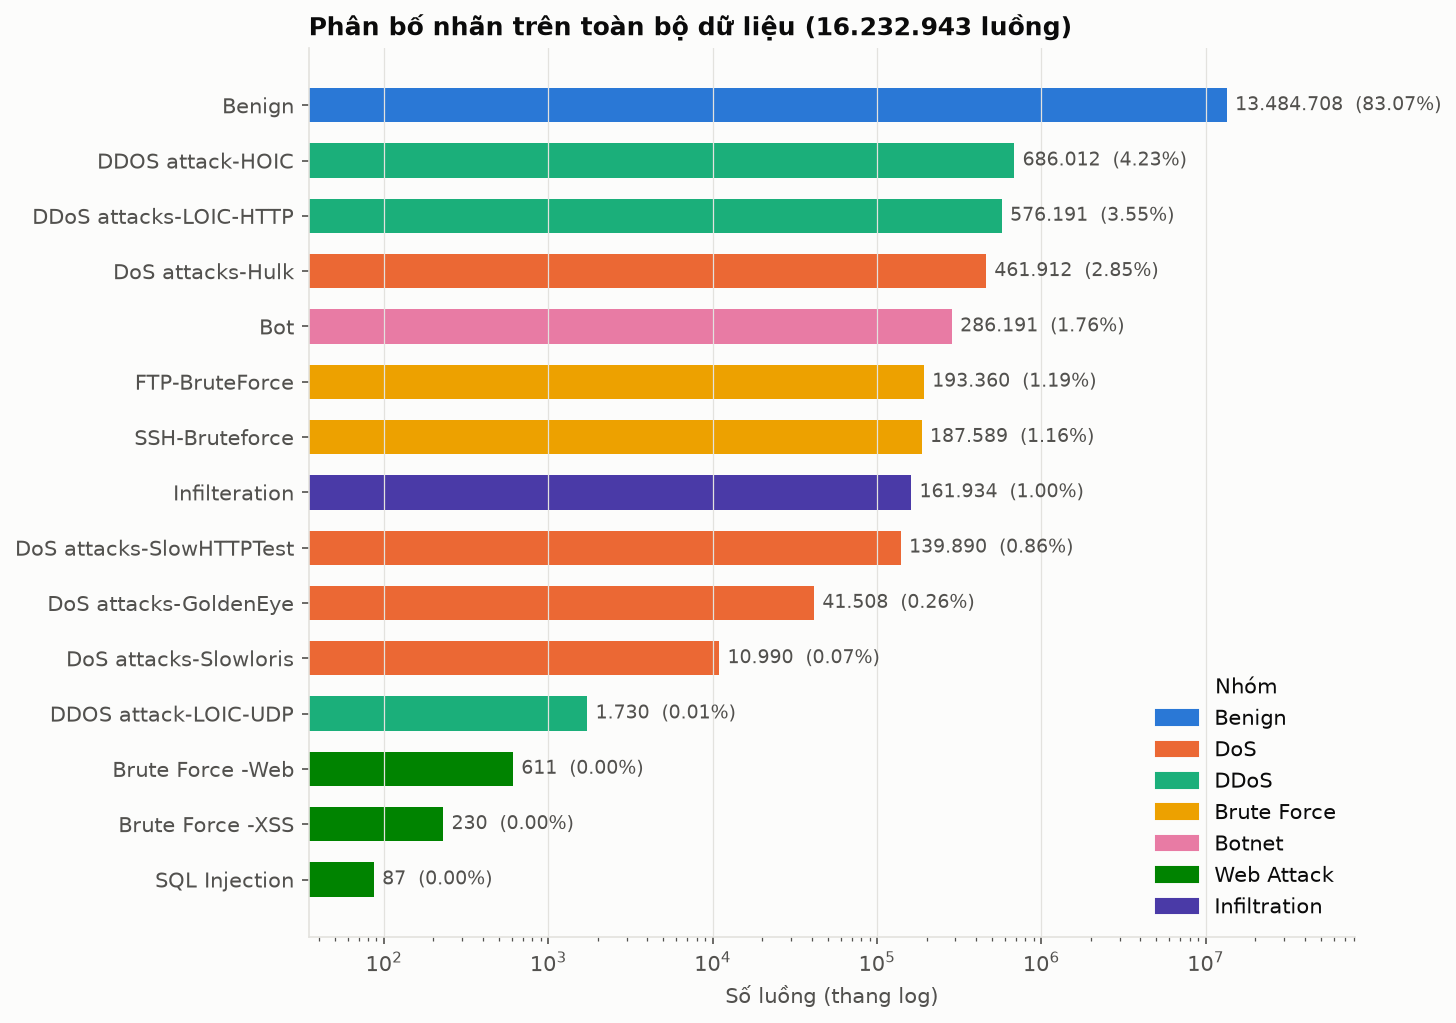

| Nhãn | Số luồng | Tỉ lệ |
|---|---:|---:|
| Benign | 13.484.708 | 83,07% |
| DDOS attack-HOIC | 686.012 | 4,23% |
| DDoS attacks-LOIC-HTTP | 576.191 | 3,55% |
| DoS attacks-Hulk | 461.912 | 2,85% |
| Bot | 286.191 | 1,76% |
| FTP-BruteForce | 193.360 | 1,19% |
| SSH-Bruteforce | 187.589 | 1,16% |
| Infilteration *(viết sai chính tả trong dữ liệu gốc)* | 161.934 | 1,00% |
| DoS attacks-SlowHTTPTest | 139.890 | 0,86% |
| DoS attacks-GoldenEye | 41.508 | 0,26% |
| DoS attacks-Slowloris | 10.990 | 0,07% |
| DDOS attack-LOIC-UDP | 1.730 | 0,01% |
| Brute Force -Web | 611 | 0,004% |
| Brute Force -XSS | 230 | 0,001% |
| SQL Injection | 87 | 0,0005% |

**Rút ra:**
- Tổng lưu lượng tấn công là 2.748.235 luồng (16,93%). Bài toán nhị phân mất cân bằng vừa phải (khoảng 5:1), nhưng bài toán đa lớp **mất cân bằng cực lớn**: lớp nhỏ nhất (SQL Injection) chỉ có 87 mẫu, kém Benign hơn 150.000 lần.
- Không dùng Accuracy. Dùng Recall, F1, PR-AUC và FPR (đúng như README).
- Với đa lớp, ba lớp Web (611, 230, 87 mẫu) quá ít để huấn luyện ổn định; cần gộp thành một lớp "Web Attack" hoặc loại khỏi giai đoạn đa lớp.
- Tên nhãn không nhất quán (`DDOS` và `DDoS`, `Infilteration`) cần chuẩn hóa khi lập `label_map`.

### 2.3. Nhãn theo ngày

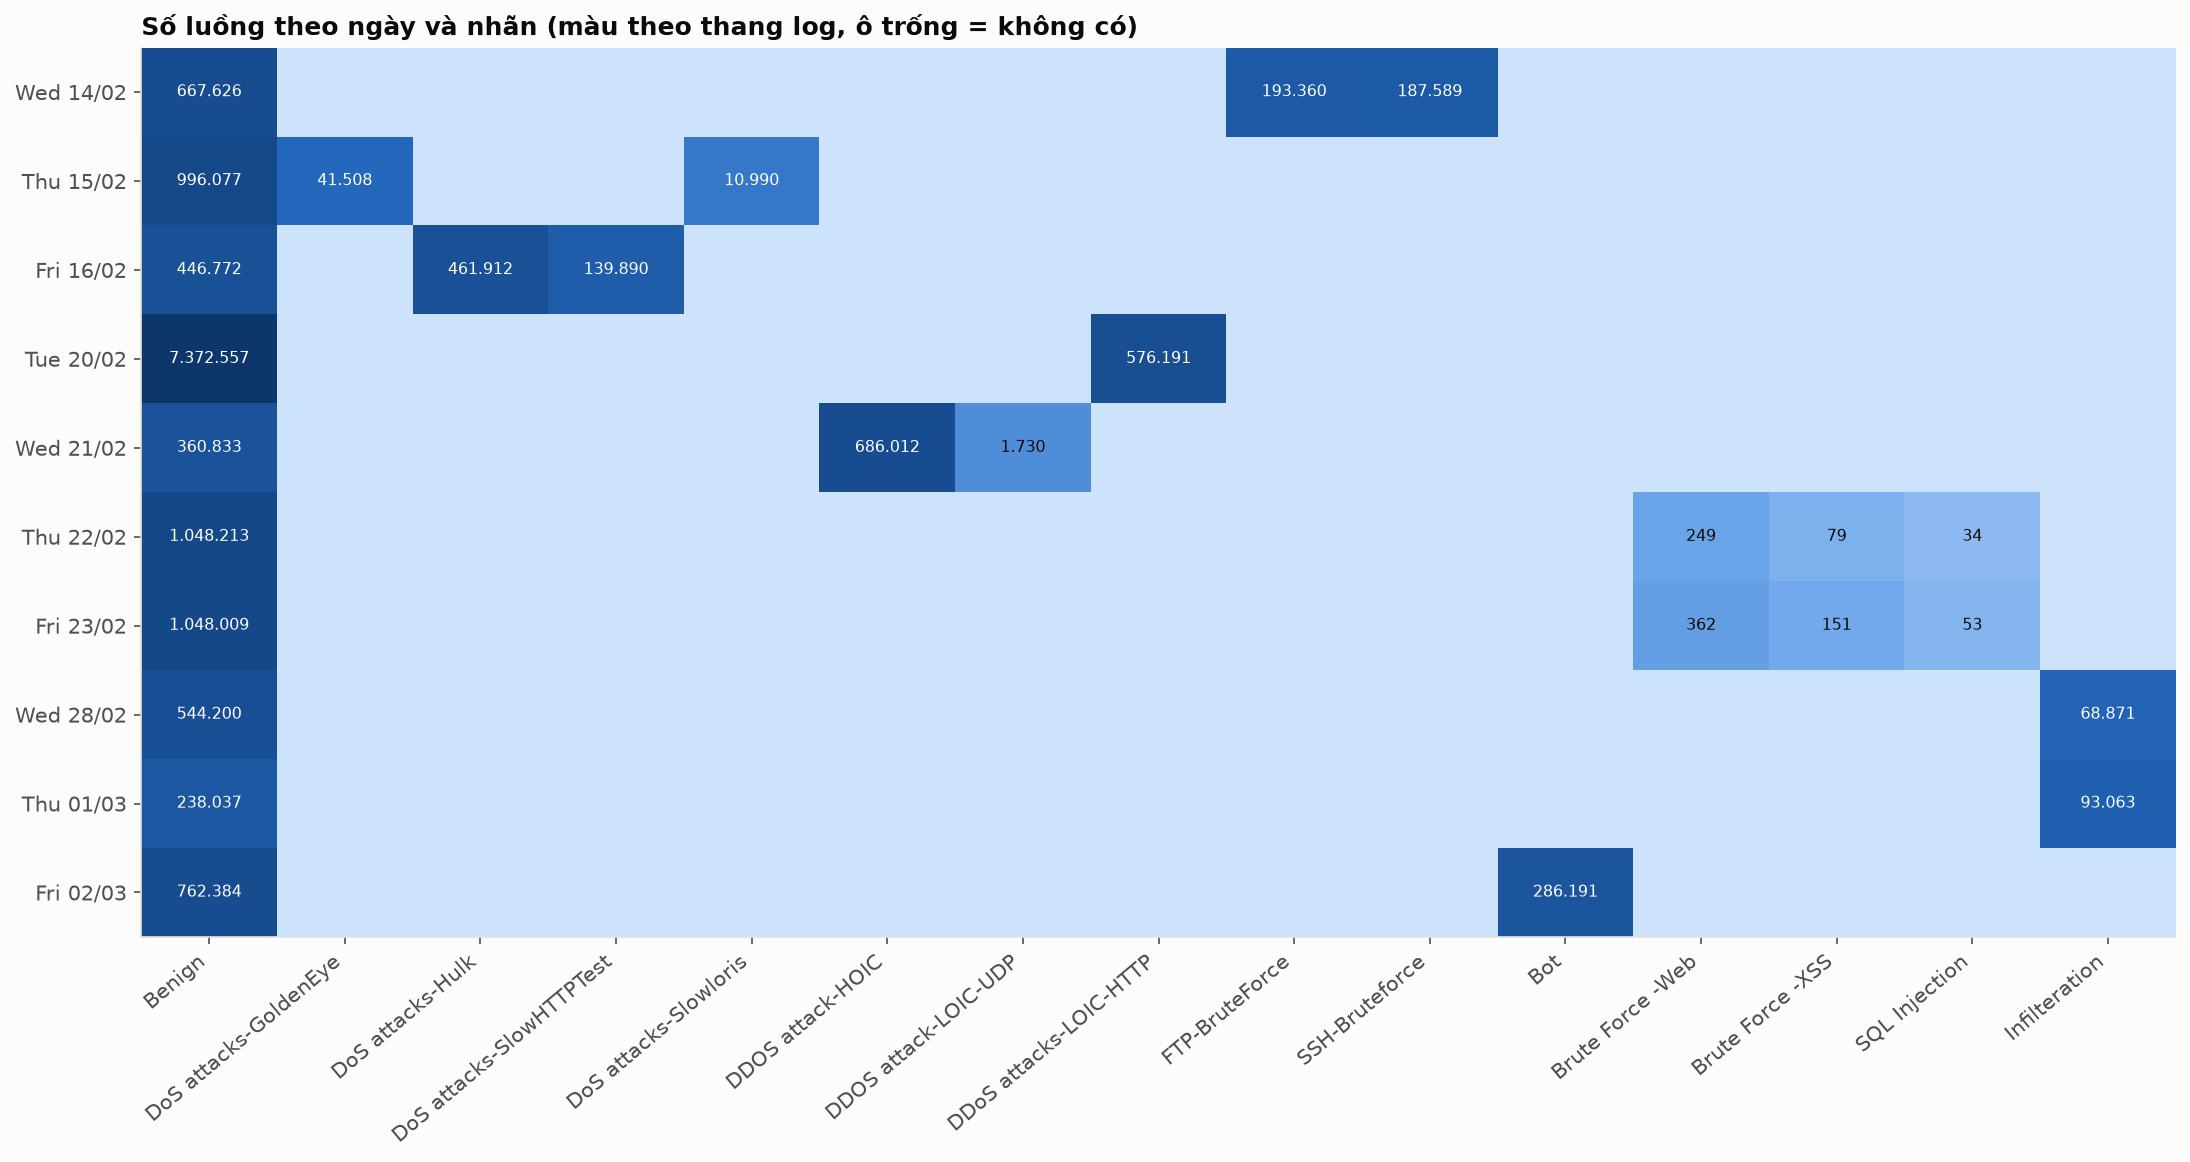

Mỗi ngày chỉ có một vài loại tấn công, và **không loại tấn công nào xuất hiện ở hai nhóm ngày khác nhau** (trừ Web ở 22/02 và 23/02, Infiltration ở 28/02 và 01/03):

| Ngày | Tấn công |
|---|---|
| 14/02 | FTP-BruteForce, SSH-Bruteforce |
| 15/02 | DoS GoldenEye, DoS Slowloris |
| 16/02 | DoS Hulk, DoS SlowHTTPTest |
| 20/02 | DDoS LOIC-HTTP |
| 21/02 | DDoS HOIC, DDoS LOIC-UDP |
| 22/02, 23/02 | Brute Force Web, Brute Force XSS, SQL Injection |
| 28/02, 01/03 | Infiltration |
| 02/03 | Bot |

**Rút ra:** chia theo ngày đồng nghĩa với việc mô hình phải nhận diện loại tấn công **chưa từng thấy**. Điều này vừa là rủi ro vừa là cơ hội cho kịch bản Drift (xem mục 5).

### 2.4. Giá trị lỗi

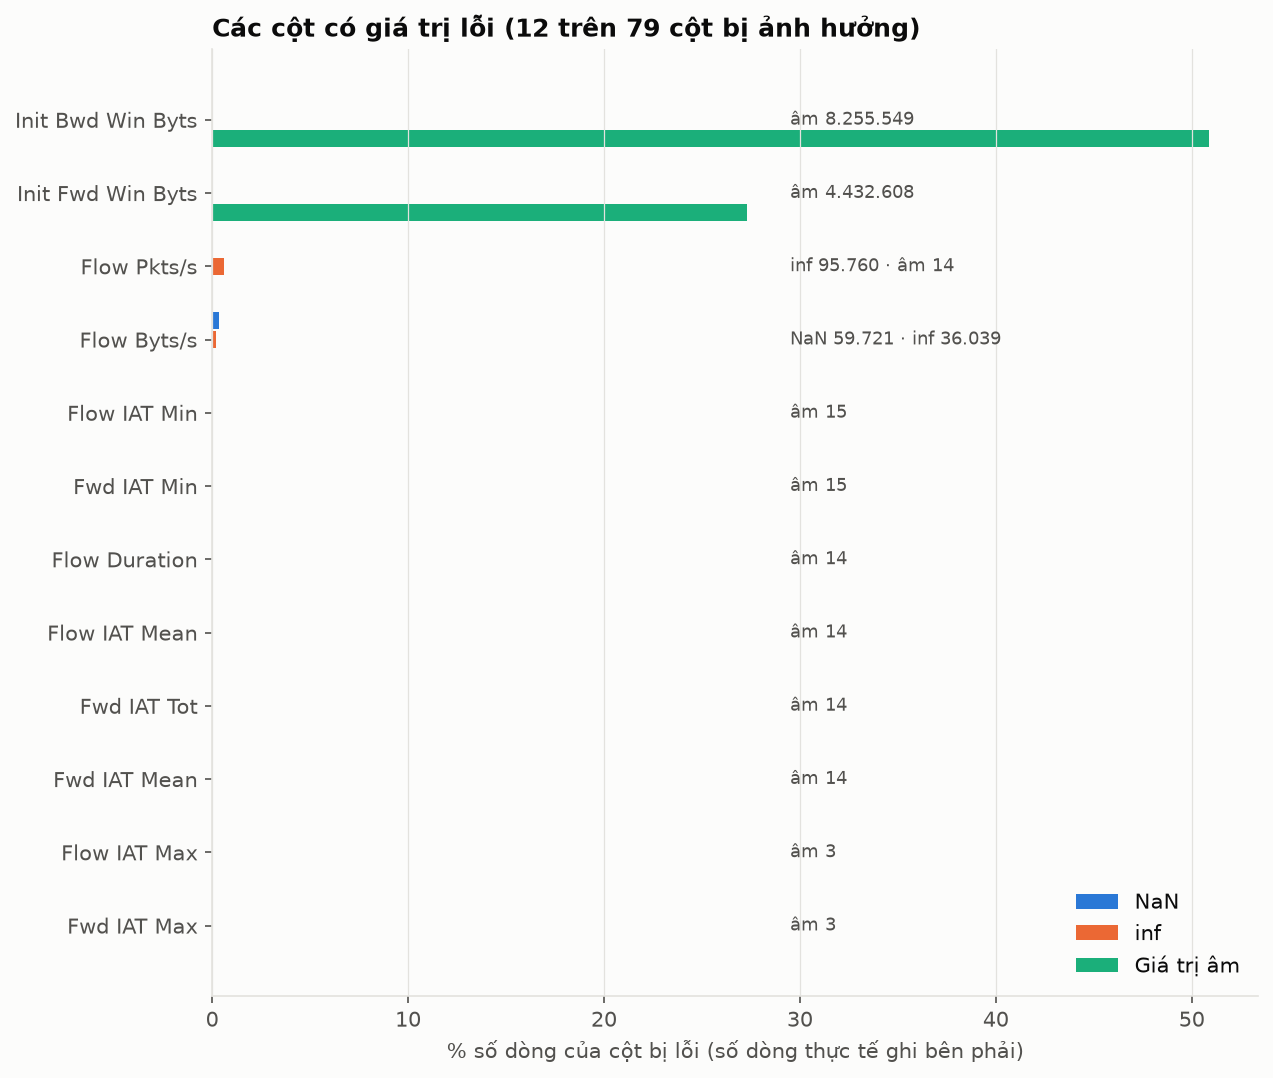

| Vấn đề | Số liệu | Cột |
|---|---|---|
| `inf` | 131.799 giá trị | `Flow Pkts/s` (95.760), `Flow Byts/s` (36.039) |
| `NaN` | 59.721 giá trị | chỉ `Flow Byts/s` |
| Giá trị âm ở cột bắt buộc không âm | 14 dòng | `Flow Duration`, `Flow IAT *`, `Fwd IAT *`, `Flow Pkts/s` (giá trị rất âm, cỡ −9×10¹¹) |
| Giá trị −1 ở cột cửa sổ TCP | 4.432.608 (27,3%) và 8.255.549 (50,9%) | `Init Fwd Win Byts`, `Init Bwd Win Byts` |
| Cột hằng số (phương sai 0) | 8 cột | `Bwd PSH Flags`, `Bwd URG Flags`, `Fwd Byts/b Avg`, `Fwd Pkts/b Avg`, `Fwd Blk Rate Avg`, `Bwd Byts/b Avg`, `Bwd Pkts/b Avg`, `Bwd Blk Rate Avg` |
| Dòng header lặp trong dữ liệu | 59 dòng | file 16/02 (1), 28/02 (33), 01/03 (25) |
| Dòng `Timestamp` sai năm (1970) | 14 dòng, **đều là Benign** | 14/02 (5), 22/02 (9) |
| Cột chỉ có ở một file | 4 cột `Flow ID`, `Src IP`, `Src Port`, `Dst IP` | chỉ file 20/02 |

**Rút ra:**
- Lỗi `inf`/`NaN` rất ít (tối đa 191.520 giá trị, dưới 1,2% số dòng) nên xóa dòng là chấp nhận được.
- Giá trị −1 ở `Init Fwd/Bwd Win Byts` **chiếm tới 27% và 51%** số dòng. Đây rất có thể là giá trị "không có cửa sổ" do CICFlowMeter gán chứ không phải lỗi; **không được xóa** các dòng này. Nên giữ nguyên hoặc thêm cột cờ.
- 14 dòng có thời lượng âm cực lớn là lỗi thật và nên loại.
- Bốn cột chỉ có ở file 20/02 là định danh (IP, cổng, Flow ID), vốn phải bỏ để tránh rò rỉ, nên sự khác biệt này không gây hại sau khi bỏ.

### 2.5. Trùng lặp

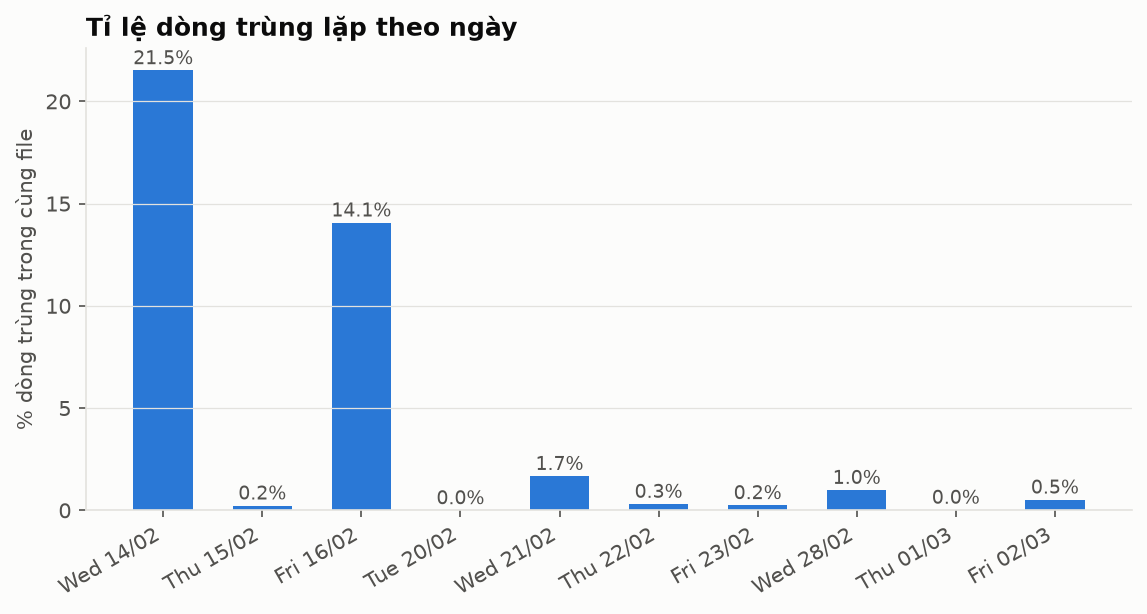

Trùng lặp tập trung ở hai ngày (14/02 và 16/02, chiếm 91% tổng số dòng trùng). Kiểm tra theo nhãn:

| File | Dòng trùng | Phân bổ theo nhãn |
|---|---:|---|
| 14/02 | 225.628 | FTP-BruteForce 154.008 (80% lớp này), SSH-Bruteforce 70.267 (37%), Benign 1.353 |
| 16/02 | 147.586 | SlowHTTPTest 120.428 (86% lớp này), Hulk 27.039 (6%), Benign 119 |

Nếu bỏ qua cột `Timestamp` khi so sánh, số dòng trùng tăng lên 373.760 (14/02) và 456.673 (16/02).

**Rút ra:** các dòng trùng **chủ yếu là luồng tấn công** (công cụ tấn công gửi lặp đi lặp lại cùng một mẫu gói tin), không phải rác. Có hai hệ quả:
1. Nếu không loại trùng trước khi chia tập, cùng một mẫu sẽ rơi vào cả train và test, khiến kết quả đẹp giả (rò rỉ).
2. Nếu loại trùng, các lớp FTP-BruteForce và SlowHTTPTest **mất 80% đến 86% số mẫu**.

Đây là quyết định cần cân nhắc (xem mục 3).

### 2.6. Tương quan giữa các đặc trưng

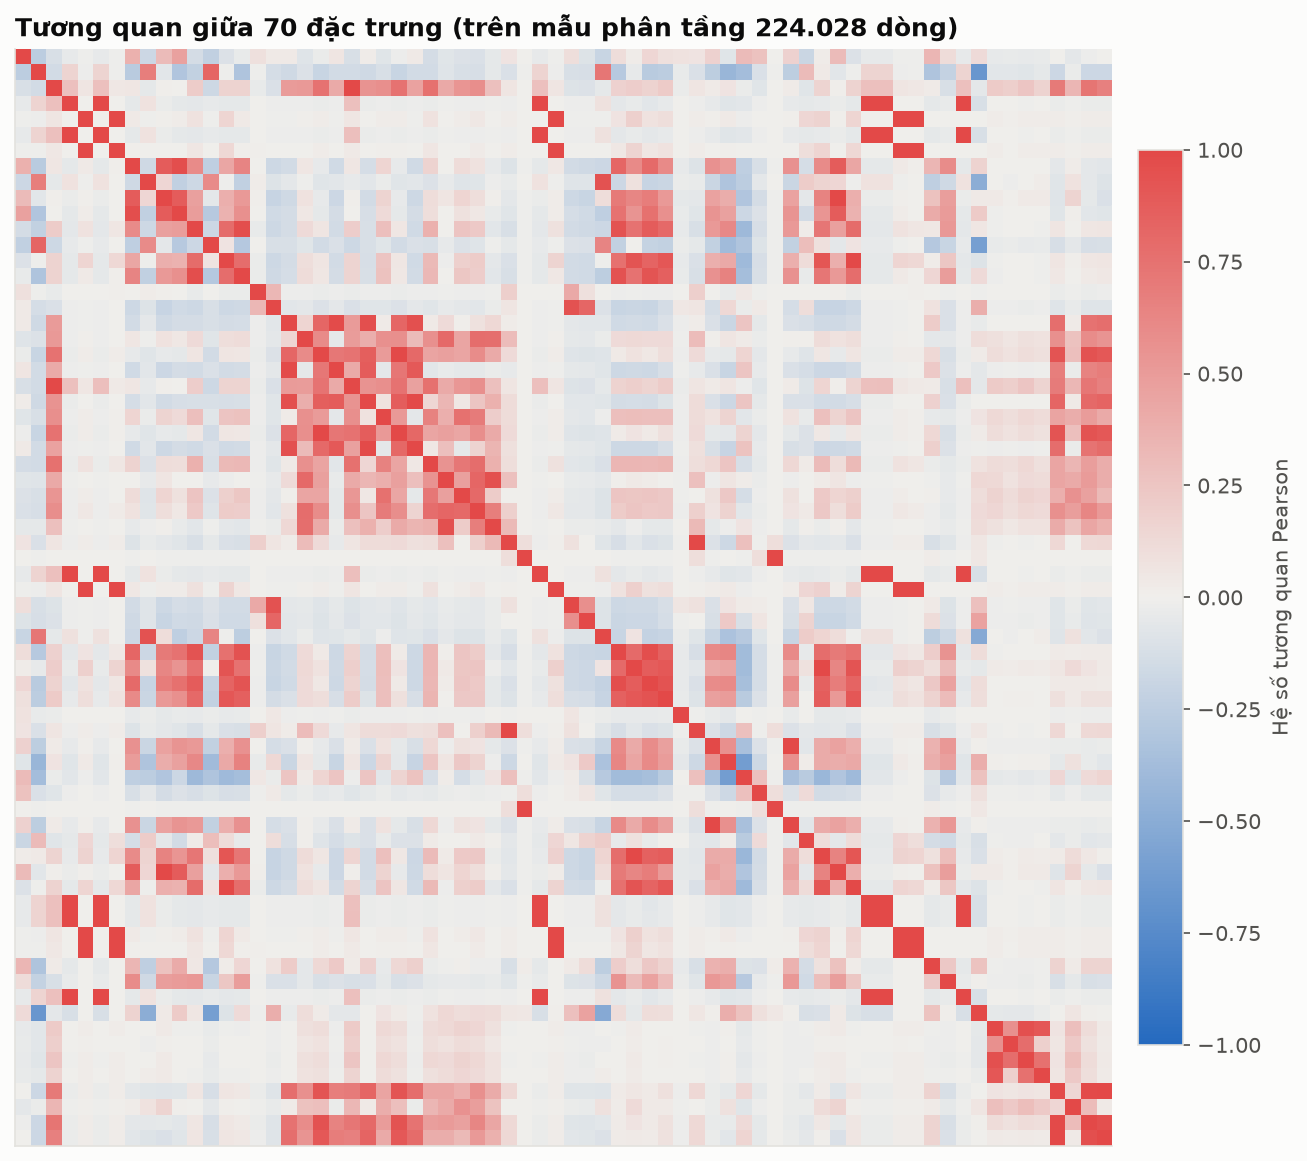

Trên mẫu phân tầng 224.028 dòng, 70 đặc trưng có biến thiên, có **34 cặp** với |r| ≥ 0,99. Ví dụ các cặp gần như giống hệt nhau:

| Cặp | r |
|---|---:|
| `Fwd Pkt Len Mean` và `Fwd Seg Size Avg` | 1,00 |
| `Bwd Pkt Len Mean` và `Bwd Seg Size Avg` | 1,00 |
| `Tot Fwd Pkts` và `Subflow Fwd Pkts` | 1,00 |
| `Tot Bwd Pkts` và `Subflow Bwd Pkts` | 1,00 |
| `TotLen Fwd Pkts` và `Subflow Fwd Byts` | 1,00 |
| `RST Flag Cnt` và `ECE Flag Cnt` | 1,00 |

**Rút ra:** có thể bỏ bớt đặc trưng thừa (giữ một đặc trưng đại diện mỗi nhóm) mà không mất thông tin; giúp mô hình nhẹ hơn và Logistic Regression ổn định hơn. Mẫu dùng ở đây là mẫu phân tầng (không tỉ lệ thật), nên hệ số tương quan chỉ mang tính tham khảo.

### 2.7. Benign so với Attack

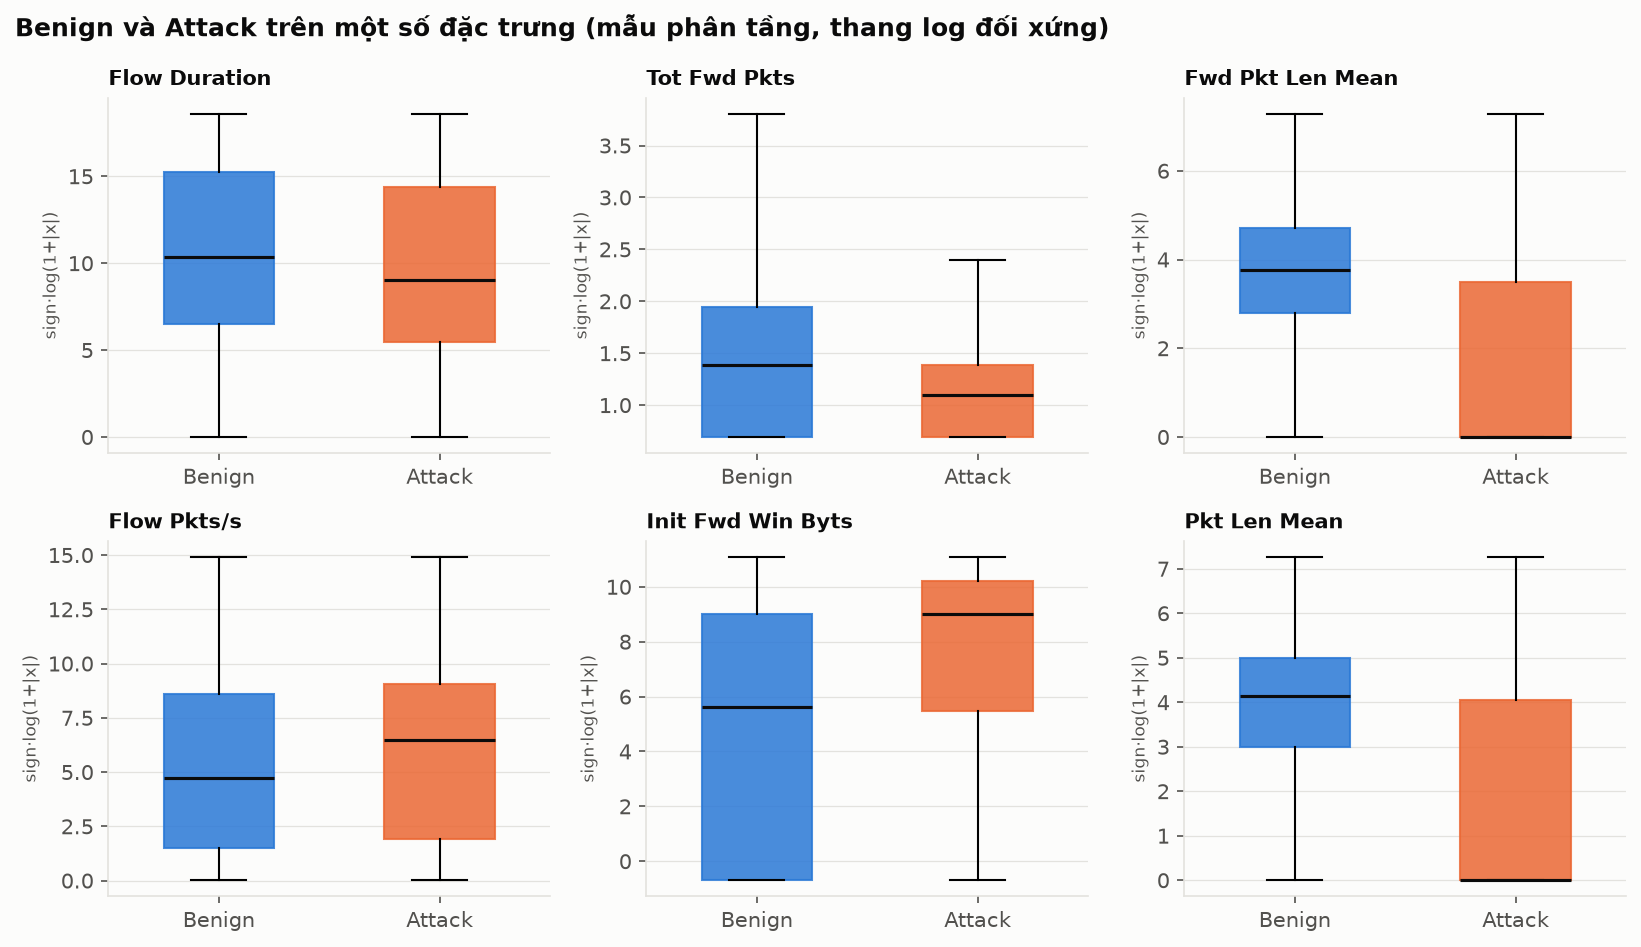

Trên các đặc trưng được chọn, phân phối của Benign và Attack **chồng lấn lớn** (ví dụ `Flow Duration`, `Flow Pkts/s`), nhưng khác biệt rõ ở một số đặc trưng như `Fwd Pkt Len Mean` và `Pkt Len Mean` (Attack có trung vị gần 0, tức nhiều gói không mang dữ liệu), hoặc `Init Fwd Win Byts` (Attack cao hơn). Không đặc trưng đơn lẻ nào đủ để phân tách, nên cần mô hình kết hợp nhiều đặc trưng (đúng lý do chọn XGBoost). Biểu đồ dùng mẫu phân tầng, không phản ánh tỉ lệ thật.

### 2.8. Thời gian

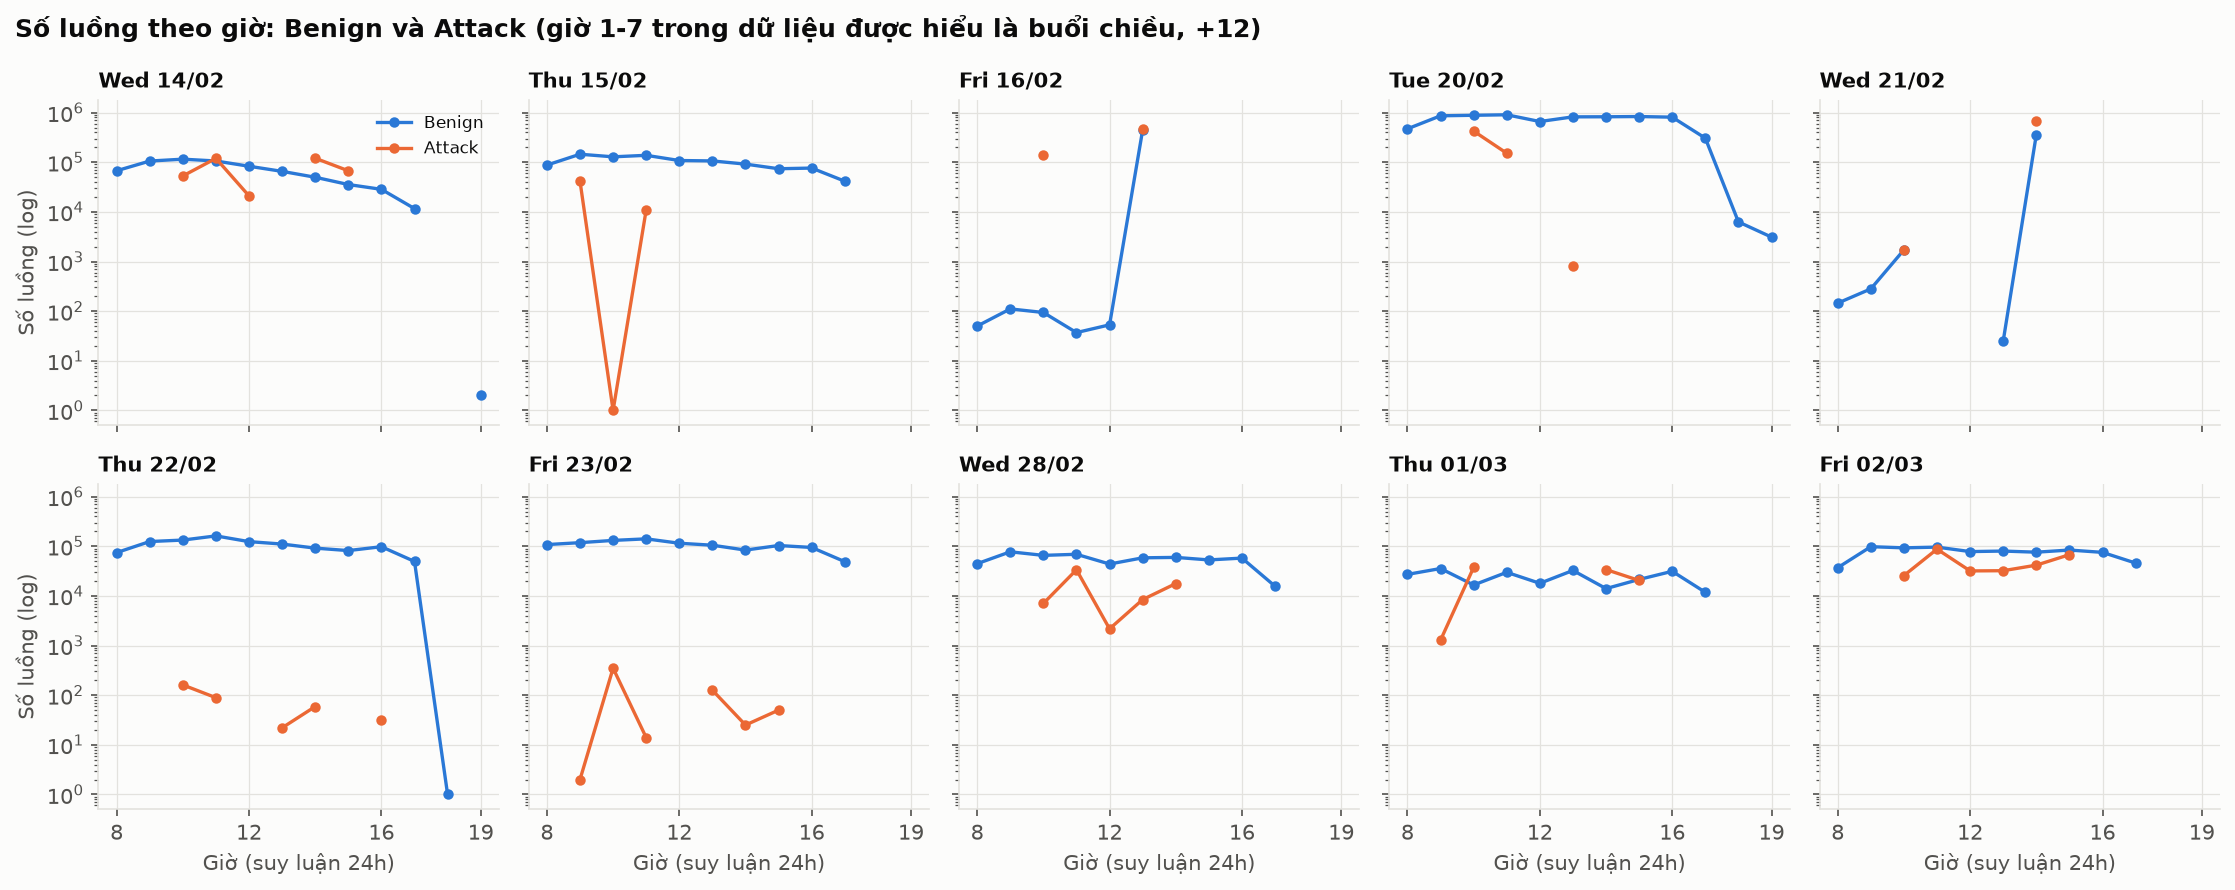

Phát hiện quan trọng cho việc chia theo thời gian:
- Ở **cả 10 ngày chỉ có giờ từ 1 đến 12**, không có giờ 0 hay 13 đến 23. Đây là dấu hiệu của **đồng hồ 12 giờ mất AM/PM**.
- Giờ 6 và 7 hầu như vắng mặt, còn giờ 8 đến 12 và 1 đến 5 có nhiều dữ liệu, khớp với giờ làm việc 8h đến 17h nếu hiểu giờ 1 đến 5 là buổi chiều (13h đến 17h). Do đó biểu đồ trên **suy luận** giờ 1 đến 7 là buổi chiều (cộng 12). Đây là giả định, chưa được tài liệu gốc xác nhận.
- **Không file nào được sắp theo thứ tự thời gian.** Không thể chia theo "đầu ngày, cuối ngày" chỉ bằng thứ tự dòng.
- Ở hai ngày 16/02 và 21/02, dữ liệu dồn vào rất ít giờ: ngày 16/02 có 86,6% luồng ở giờ 1 và 13,3% ở giờ 10; ngày 21/02 có 99,6% luồng ở giờ 2 (giá trị giờ gốc trong dữ liệu). Chia theo giờ không có ý nghĩa với hai ngày này.
- Tấn công thường xảy ra trong khoảng 9h đến 16h (suy luận).

---

## 3. Quyết định xử lý rút ra từ EDA

| # | Vấn đề | Quyết định đề xuất | Căn cứ |
|---|---|---|---|
| 1 | Header lặp (59 dòng) | Loại | Mục 2.4 |
| 2 | `Timestamp` sai năm (14 dòng Benign) | Loại | Mục 2.4 |
| 3 | `inf`/`NaN` ở `Flow Byts/s`, `Flow Pkts/s` | Đổi `inf` thành `NaN`, loại dòng (dưới 1,2%) | Mục 2.4 |
| 4 | Thời lượng/IAT âm (14 dòng) | Loại | Mục 2.4 |
| 5 | `Init Fwd/Bwd Win Byts = -1` | **Giữ**, có thể thêm cột cờ | 27% và 51% số dòng, không phải lỗi |
| 6 | 8 cột hằng số | Loại khỏi đặc trưng | Mục 2.4 |
| 7 | Cột định danh (`Flow ID`, `Src IP`, `Dst IP`, `Src Port`) và `Timestamp` | Không dùng làm đặc trưng (chống rò rỉ); `Timestamp` chỉ dùng để chia tập | Mục 2.4, 2.8 |
| 8 | Đặc trưng tương quan ≥ 0,99 | Giữ một đại diện mỗi nhóm | Mục 2.6 |
| 9 | Dòng trùng (410.660) | **Cần nhóm quyết định**, xem dưới | Mục 2.5 |
| 10 | Nhãn không nhất quán | Chuẩn hóa tên nhãn, lập `label_map.json` | Mục 2.2 |
| 11 | Lớp Web quá ít (611, 230, 87) | Gộp thành "Web Attack" khi làm đa lớp | Mục 2.2 |
| 12 | Mất cân bằng lớp | `scale_pos_weight`/`class_weight` trước; chỉ cân bằng trên train | Mục 2.2 |
| 13 | Ngày 20/02 chiếm 49% dữ liệu, 93% là Benign | Lấy mẫu Benign của ngày này khi huấn luyện (xem mục 5) | Mục 2.1, 2.3 |
| 14 | `Dst Port` và `Protocol` có làm đặc trưng không | **Chưa quyết.** Cổng đích có thể khiến mô hình học theo dịch vụ thay vì hành vi; cần thử huấn luyện có và không có hai cột này để so sánh | Chưa có số liệu (EDA chưa phân tích hai cột này) |

**Quyết định #9 (trùng lặp), hai phương án:**
- **(a) Loại trùng trước khi chia tập (khuyến nghị).** Tránh rò rỉ giữa train và test; chấp nhận mất phần lớn mẫu lặp của FTP-BruteForce và SlowHTTPTest. Đây vẫn là tập đủ lớn (FTP còn khoảng 39 nghìn mẫu).
- **(b) Giữ trùng, nhưng gom các bản trùng vào cùng một tập khi chia.** Giữ được phân bố thật, nhưng phức tạp hơn.

---

## 4. Pipeline dữ liệu

```mermaid
flowchart LR
    A[(AWS S3<br/>CSE-CIC-IDS2018)] -->|1. download| B[data/raw<br/>10 CSV bất biến]
    B -->|2. ingest<br/>chuẩn hóa schema| C[data/interim<br/>Parquet]
    C -->|3. validate| D{Đạt?}
    D -- Không --> X[Dừng và báo lỗi]
    D -- Có --> E[4. clean<br/>header · năm 1970 · inf/NaN · âm · trùng]
    E --> F[5. label<br/>nhị phân / đa lớp]
    F --> G[6. split]
    G --> H[data/processed<br/>train · val · test]
    G --> I[data/processed<br/>production_sim]
    H --> J[7. preprocess<br/>scale · cân bằng lớp · lưu artifact]
    J --> K[Huấn luyện / MLflow]
    I --> L[Giám sát Drift / Evidently]
```

Trạng thái cài đặt: bước 1 (`download.py`) và phân tích EDA (`eda_stats.py`, `eda_timestamps.py`, `eda_plots.py`) đã có; các bước 2 đến 7 chưa cài đặt.

---

## 5. Chia tập và kịch bản Drift

Căn cứ từ EDA: tấn công phân bố theo ngày (mục 2.3), file không sắp theo thời gian và mất AM/PM (mục 2.8), dòng trùng gây rò rỉ (mục 2.5).

**Đề xuất (cần nhóm xác nhận):**

| Giai đoạn | Ngày | Tấn công có mặt | Dùng cho |
|---|---|---|---|
| **Huấn luyện ban đầu** | 14/02, 15/02, 16/02, 20/02, 21/02 | Brute Force (FTP, SSH), DoS (4 loại), DDoS (3 loại) | Train / Val / Test (chia bên dưới) |
| **Vận hành mô phỏng** | 22/02, 23/02, 28/02, 01/03, 02/03 | Web, Infiltration, Bot | `production_sim`: Drift, giám sát, tái huấn luyện |

Lý do:
- Ba nhóm tấn công mới (Web, Infiltration, Bot) chỉ xuất hiện ở giai đoạn sau, nên mô hình ban đầu **chưa từng thấy** chúng. Điều này tạo kịch bản Drift tự nhiên và thuyết phục cho Giai đoạn 6: Recall giảm trên dữ liệu mới, kích hoạt tái huấn luyện, rồi so sánh trước và sau.
- Chia theo ngày thuần túy trong giai đoạn đầu sẽ khiến Val/Test chứa loại tấn công mà Train chưa thấy. Để tránh điều này, trong giai đoạn huấn luyện ban đầu nên **chia trong từng ngày** (mỗi tập có mặt mọi loại tấn công), sau khi đã loại trùng.
- Vì thứ tự dòng và giờ không đáng tin cậy, cách chia trong ngày cần được thiết kế cẩn thận (ví dụ chia theo khối liên tiếp theo thứ tự dòng, hoặc theo giờ suy luận) và phải kiểm tra rò rỉ. **Cách chia cụ thể chưa chốt.**

Việc khác:
- Ngày 20/02 có 7,37 triệu Benign. Nên lấy mẫu Benign của ngày này để không áp đảo tập train.
- Mọi bước học tham số (scaler, chọn đặc trưng, cân bằng lớp) chỉ `fit` trên Train.

---

## 6. Version hóa và tái lập

| Đối tượng | Cách quản lý |
|---|---|
| Mã xử lý | Git |
| Tham số | `params.yaml` (cột loại bỏ, cách chia, seed, ngưỡng) |
| Dữ liệu raw | Không commit; `data/raw/MANIFEST.json` (SHA-256 và dung lượng từng file) |
| Dữ liệu xử lý | Parquet trong `data/interim/` và `data/processed/`; ghi hash vào MLflow khi huấn luyện |
| Phiên bản dữ liệu (tùy chọn) | DVC (ngoài danh sách công cụ của README); nếu không dùng, tối thiểu log hash và `params.yaml` vào MLflow |

---

## 7. Cấu trúc thư mục và đầu ra

```text
CIC-IDS-MLOps/
├── data/
│   ├── raw/                      # 10 CSV + MANIFEST.json (không commit)
│   ├── interim/                  # eda_sample.parquet (mẫu phân tầng 224.028 dòng)
│   └── processed/                # (chưa có) train / val / test / production_sim
├── reports/data/
│   ├── eda_stats.json            # thống kê đầy đủ từng cột, từng ngày
│   ├── eda_summary.json          # số liệu tóm tắt dùng trong báo cáo này
│   ├── timestamp_check.json      # kiểm tra giờ, dòng lệch ngày
│   └── figures/                  # 7 biểu đồ 01_ đến 07_
├── src/data/
│   ├── download.py               # tạo MANIFEST.json
│   ├── eda_stats.py              # thống kê streaming, tạo mẫu phân tầng
│   ├── eda_timestamps.py         # kiểm tra Timestamp
│   ├── eda_plots.py              # vẽ biểu đồ
│   ├── build_report_html.py      # docs/DATA.md -> docs/DATA_report.html
│   └── md_to_ipynb.py            # Markdown -> notebook trong colab/
├── docs/                         # file mở bằng trình xem gốc
│   ├── DATA.md                   # báo cáo này
│   ├── DATA_report.html          # bản HTML, ảnh nhúng sẵn
│   └── HUONG_DAN_DATA.md         # hướng dẫn từng bước để học
├── colab/                        # file mở bằng Google Colab / Jupyter
│   ├── DATA_report.ipynb
│   ├── HUONG_DAN_DATA.ipynb
│   └── README.ipynb
└── README.md                     # README gốc của dự án
```

Về mẫu `eda_sample.parquet`: lấy tối đa 4.000 dòng mỗi nhãn mỗi chunk 500.000 dòng, nên **không tỉ lệ thật**; chỉ dùng cho biểu đồ tương quan và boxplot. Các số đếm (nhãn, ngày, lỗi, trùng) lấy từ toàn bộ dữ liệu.

---

## 8. Cách chạy lại

```bash
cd CIC-IDS-MLOps
source .venv/bin/activate                  # hoặc dùng ./.venv/bin/python

# 1. Tải dữ liệu (6,4 GiB). Dùng "python -m awscli" nếu đường dẫn có dấu/khoảng trắng
python -m awscli s3 sync --no-sign-request --region ca-central-1 \
  "s3://cse-cic-ids2018/Processed Traffic Data for ML Algorithms/" data/raw/

# 2. Checksum
python src/data/download.py

# 3. EDA (khoảng 5 phút, file 20/02 mất khoảng 2 phút)
python src/data/eda_stats.py
python src/data/eda_timestamps.py
python src/data/eda_plots.py

# 4. Cập nhật bản HTML và notebook sau khi sửa file .md
python src/data/build_report_html.py
python src/data/md_to_ipynb.py docs/DATA.md docs/HUONG_DAN_DATA.md README.md
```

---

## 9. Rủi ro và lưu ý

| Rủi ro | Biện pháp |
|---|---|
| File có thể bị cắt ở 1.048.575 dòng | Đối chiếu với nguồn gốc/tài liệu CIC; ghi vào hạn chế của dữ liệu |
| Mất AM/PM nên giờ không đáng tin | Không dùng giờ làm đặc trưng; nếu chia theo giờ phải ghi rõ giả định |
| Dòng trùng gây rò rỉ nếu chia ngẫu nhiên | Loại trùng trước khi chia, hoặc gom bản trùng vào cùng một tập |
| Lớp hiếm (Web: 87 đến 611 mẫu) | Gộp lớp hoặc loại khỏi đa lớp |
| Ngày 20/02 chiếm 49% dữ liệu | Lấy mẫu Benign |
| Xóa nhầm giá trị −1 hợp lệ | Giữ `Init Fwd/Bwd Win Byts = -1` |
| Hết RAM với file 4 GB | Đọc theo chunk; chuyển sang Parquet và downcast |
| Train–serve skew | Dùng chung artifact tiền xử lý (`scaler`, danh sách đặc trưng) giữa huấn luyện và API |
| Giấy phép | Kiểm tra điều khoản sử dụng của CIC trước khi chia sẻ lại dữ liệu |

---

## 10. Checklist

- [x] Tải đủ 10 file, kiểm tra dung lượng và tạo `MANIFEST.json`
- [x] EDA: nhãn, theo ngày, giá trị lỗi, trùng lặp, tương quan, thời gian
- [x] Phát hiện vấn đề dữ liệu (AM/PM, trùng lặp, file bị cắt, giá trị −1)
- [ ] Nhóm xác nhận quyết định #9 (trùng lặp) và cách chia tập (mục 5)
- [ ] `params.yaml`
- [ ] `ingest.py`: chuẩn hóa schema, chuyển Parquet
- [ ] `validate.py` và báo cáo
- [ ] `clean.py` và `cleaning_report.json`
- [ ] `label.py` (nhị phân; chuẩn bị sẵn đa lớp)
- [ ] `split.py`: train/val/test và `production_sim`
- [ ] `preprocess.py`: scaler, đặc trưng, cân bằng lớp; lưu artifact
- [ ] Test cho các bước trên (`tests/data/`)
- [ ] Tích hợp vào DAG Airflow (Giai đoạn 5)

---

## 11. Data Card

| Hạng mục | Nội dung |
|---|---|
| Tên | CSE-CIC-IDS2018, thư mục "Processed Traffic Data for ML Algorithms" |
| Nguồn gốc | CSE và CIC (Canadian Institute for Cybersecurity); thu thập 14/02 đến 02/03/2018 trong môi trường doanh nghiệp mô phỏng |
| Giấy phép / điều khoản | Chưa kiểm tra; cần xem điều khoản trên trang CIC trước khi chia sẻ lại |
| Quy mô | 16.232.943 luồng, 10 file, 6,4 GiB; 79 đặc trưng số và nhãn (80 cột chung) |
| Nhãn | 15 nhãn: Benign (83,07%) và 14 loại tấn công (16,93%) |
| Phân bố theo ngày | Mỗi ngày chỉ có 1 đến 3 loại tấn công (mục 2.3) |
| Vấn đề chất lượng | Header lặp (59), `Timestamp` sai năm (14), `inf` (131.799), `NaN` (59.721), thời lượng âm (14), 8 cột hằng số, dòng trùng (410.660, tập trung ở 14/02 và 16/02), tên nhãn không nhất quán |
| Vấn đề thời gian | Đồng hồ 12h mất AM/PM; file không sắp theo thời gian |
| Giới hạn đã biết | Dữ liệu mô phỏng, có thể khác lưu lượng thực; các file (trừ 20/02, 28/02, 01/03) có đúng 1.048.575 dòng, nghi bị cắt; mất cân bằng lớp nặng; lớp Web rất ít mẫu |
| Cột định danh | `Flow ID`, `Src IP`, `Dst IP`, `Src Port` chỉ có trong file 20/02; không dùng làm đặc trưng |
| Phiên bản dữ liệu | SHA-256 từng file trong `data/raw/MANIFEST.json` |